<a href="https://colab.research.google.com/github/vishnu1901-2006/NeuralNetworkWithTF/blob/main/Build_convolutions_and_perform_pooling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
from scipy.datasets import ascent
i = ascent()

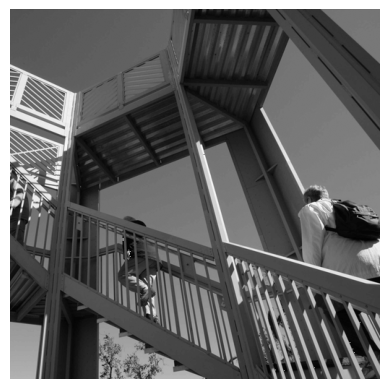

In [ ]:
import matplotlib.pyplot as plt
plt.grid(False)
plt.gray()
plt.axis('off')
plt.imshow(i)
plt.show()

In [ ]:
i_transformed = np.copy(i)
size_x = i_transformed.shape[0]
size_y = i_transformed.shape[1]

In [ ]:
# This filter detects edges nicely
# It creates a filter that only passes through sharp edges and straight lines.
# Experiment with different values for fun effects.
#filter = [ [0, 1, 0], [1, -4, 1], [0, 1, 0]]
# A couple more filters to try for fun!
filter = [ [-1, -2, -1], [0, 0, 0], [1, 2, 1]]
#filter = [ [-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
 # If all the digits in the filter don't add up to 0 or 1, you
# should probably do a weight to get it to do so
# so, for example, if your weights are 1,1,1 1,2,1 1,1,1
# They add up to 10, so you would set a weight of .1 if you want to normalize them
weight  = 1

In [ ]:
for x in range(1, size_x-1):
  for y in range(1, size_y-1):
    output_pixel = 0.0
    output_pixel = output_pixel + (float(i[x - 1, y-1]) * filter[0][0])
    output_pixel = output_pixel + (float(i[x, y-1]) * filter[0][1])
    output_pixel = output_pixel + (float(i[x + 1, y-1]) * filter[0][2])
    output_pixel = output_pixel + (float(i[x-1, y]) * filter[1][0])
    output_pixel = output_pixel + (float(i[x, y]) * filter[1][1])
    output_pixel = output_pixel + (float(i[x+1, y]) * filter[1][2])
    output_pixel = output_pixel + (float(i[x-1, y+1]) * filter[2][0])
    output_pixel = output_pixel + (float(i[x, y+1]) * filter[2][1])
    output_pixel = output_pixel + (float(i[x+1, y+1]) * filter[2][2])
    output_pixel = output_pixel * weight
    if(output_pixel<0):
      output_pixel=0
    if(output_pixel>255):
      output_pixel=255
    i_transformed[x, y] = output_pixel

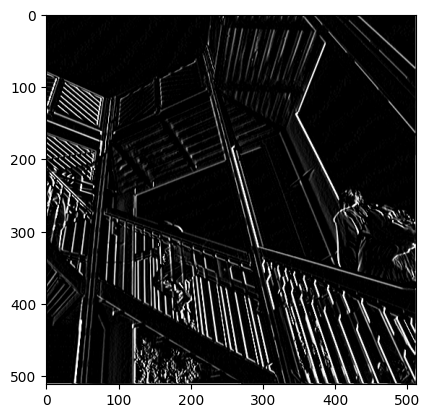

In [ ]:
plt.gray()
plt.grid(False)
plt.imshow(i_transformed)
#plt.axis('off')
plt.show()

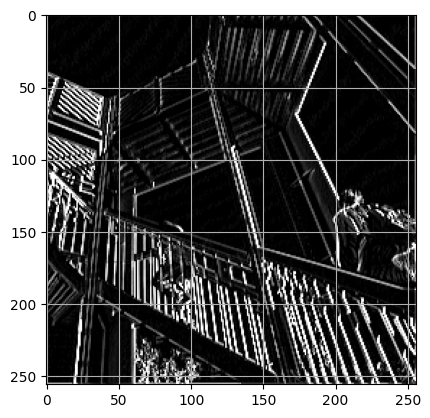

In [ ]:
new_x = int(size_x/2)
new_y = int(size_y/2)
newImage = np.zeros((new_x, new_y))

for x in range(0, size_x,2):
  for y in range(0, size_y, 2):
    pixels=[]
    pixels.append(i_transformed[x, y])
    pixels.append(i_transformed[x+1, y])
    pixels.append(i_transformed[x, y+1])
    pixels.append(i_transformed[x+1, y+1])
    pixels.sort(reverse=True)
    newImage[int(x/2), int(y/2)] = pixels[0]

plt.gray()
plt.grid()
plt.imshow(newImage)
#plt.axis('off')
plt.show()